# 01 Data exploration (simulated)

Everything here is **SIMULATED** on the German SimBench benchmark grid `1-LV-semiurb5--0-sw`; it is not utility data and not Tunisian data (`docs/LIMITATIONS.md`). The notebook only reads the committed dataset (`dataset/baseline_semiurb5`: observed, context and labels; never truth) and existing result files, and calls functions in `shahid/`. Single-day and single-week plots are illustrations, not results. Measured numbers are in `docs/CLAIMS_LEDGER.md`.

In [1]:
import sys, json
sys.path.insert(0, "..")  # repository root, so `shahid` imports work from notebooks/
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from shahid import detect, evaluate, explain, grid
from shahid.world import grid_meta
plt.rcParams.update({"figure.figsize": (9, 3.2), "axes.spines.top": False, "axes.spines.right": False})
D = "../dataset/baseline_semiurb5"
GRID = "1-LV-semiurb5--0-sw"

## The grid
One MV/LV transformer feeding several low-voltage feeders (SimBench network, REUSED).

In [2]:
net, prof = grid.load_grid(GRID)
meta = grid_meta(GRID)
print('loads:', len(net.load), '| PV units:', len(net.sgen), '| lines:', len(net.line),
      '| transformer rating (MVA):', list(net.trafo.sn_mva), '| feeders:', len(meta['feeders']))

loads:

104

| PV units:

9

| lines:

109

| transformer rating (MVA):

[0.63]

| feeders:

6

## The customers
Each load is one smart meter. `context/` maps meters to concentrators and to electrical zones (the meter sets one line opening would cut off).

In [3]:
meters = pd.read_parquet(f'{D}/context/meters.parquet')
zones = pd.read_parquet(f'{D}/context/zones.parquet')
print('meters:', len(meters), '| with PV:', int((meters.pv_kw > 0).sum()),
      '| concentrators:', meters.concentrator_id.nunique(), '| zones:', zones.zone_id.nunique())
meters.head()

meters:

104

| with PV:

9

| concentrators:

6

| zones:

109

,meter_id,concentrator_id,pv_kw
0,m000,3,0.0
1,m001,0,0.0
2,m002,3,0.0
3,m003,0,0.0
4,m004,1,0.0


## One week of load and PV (illustration)
SimBench absolute profiles summed over the grid, **before** the per-customer diversity the simulation adds (`shahid/world.py: diversify`).

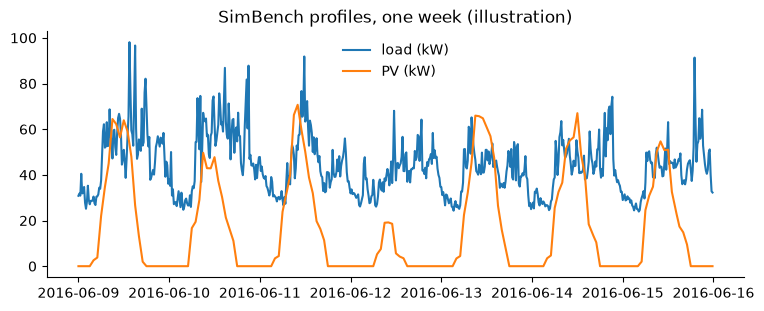

In [4]:
lp, lq, sp = grid.profile_arrays(net, prof)
week = slice(96 * 160, 96 * 167)  # 9-15 June 2016
t = pd.date_range('2016-01-01', periods=len(lp), freq='15min')[week]
plt.plot(t, lp[week].sum(1) * 1000, label='load (kW)')
plt.plot(t, sp[week].sum(1) * 1000, label='PV (kW)')
plt.legend(frameon=False); plt.title('SimBench profiles, one week (illustration)'); plt.show()

## Transformer energy against the sum of the meters
The detector's evidence is the **gap**: transformer energy minus everything the reporting meters account for (losses, unmetered energy, meter errors). Only intervals in which every meter reported are used here.

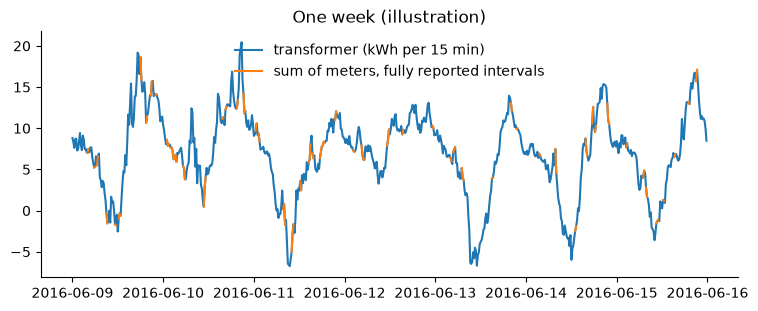

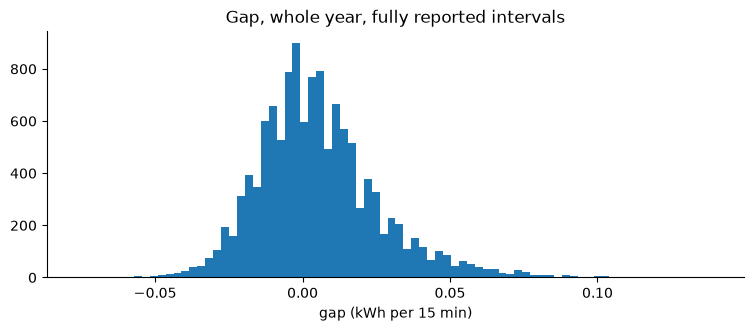

In [5]:
inputs = detect.load_inputs(D)
index, ids, E, A, T = detect.arrays(inputs)
full = np.isfinite(E).all(1)
S = np.where(full, np.nansum(E, 1), np.nan)
w = slice(96 * 160, 96 * 167)
plt.plot(index[w], T[w], label='transformer (kWh per 15 min)')
plt.plot(index[w], S[w], label='sum of meters, fully reported intervals')
plt.legend(frameon=False); plt.title('One week (illustration)'); plt.show()
plt.hist((T - S)[full], bins=80); plt.xlabel('gap (kWh per 15 min)'); plt.title('Gap, whole year, fully reported intervals'); plt.show()

## Effect of the diversity setting
SimBench loads are scaled copies of about ten shapes. The simulator adds per-customer variation with an uncalibrated knob `d` (ASSUMPTION A-DIV). Source: `results/cp1_diversity.json` (ledger C1-07, C1-08).

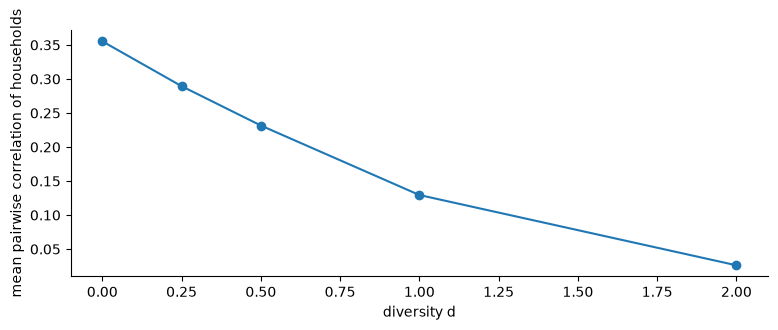

In [6]:
div = json.load(open('../results/cp1_diversity.json'))['by_d']
d = sorted(div, key=float)
plt.plot([float(x) for x in d], [div[x]['pairwise_corr_mean'] for x in d], 'o-')
plt.xlabel('diversity d'); plt.ylabel('mean pairwise correlation of households'); plt.show()

## Missing and delayed readings
Cell-level labels record why a reading is missing or late (ledger C3-03). Delays are measured from the end of the interval.

cause
DELAYED          108897
RANDOM_LOSS       36743
NORMAL                0
COMMS_FAILURE         0
OUTAGE                0
Name: count, dtype: int64

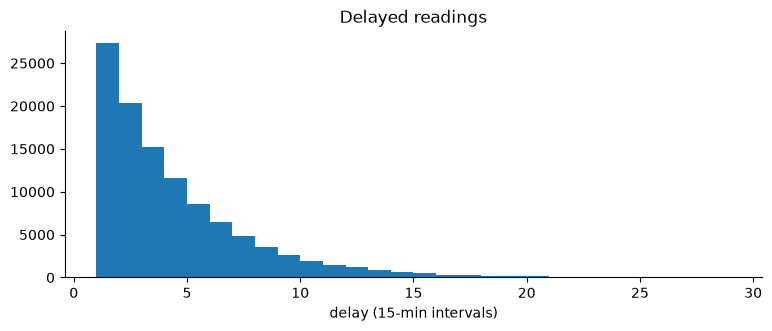

In [7]:
cells = pd.read_parquet(f'{D}/labels/cells.parquet')
print(cells.cause.value_counts())
r = inputs['readings']
late = (r.arrival_ts - r.interval_start - detect.STEP) / detect.STEP
plt.hist(late[late > 0], bins=range(1, 30)); plt.xlabel('delay (15-min intervals)'); plt.title('Delayed readings'); plt.show()